# Data Contracts & Schema Registries

In a streaming system the producer and its consumers are separate teams and separate deployments. If the producer
renames a field, every consumer can break at 3 a.m. Two tools prevent this:

- A **schema registry** stores every version of a topic's schema and **rejects incompatible changes** before they
  reach the topic. Events carry only a small schema ID; the bytes are compact binary (Avro, Protobuf, JSON Schema).
- A **data contract** is the wider agreement: schema plus meaning, quality rules, freshness, ownership and support.

**After this lesson you can:**

1. Produce and consume Avro events through Confluent Schema Registry.
2. Explain BACKWARD, FORWARD and FULL compatibility and predict which schema changes pass.
3. Read new data with an old schema (Avro schema resolution).
4. Write a data contract in YAML and validate records against it.

**Data:** NYC taxi trips (January 2024) as events.
**Services:** Kafka + Schema Registry: `docker compose -f docker/compose.yml --profile streaming up -d kafka schema-registry`
(registry on http://localhost:8081).

In [1]:
import io
import json
import sys
import time
from pathlib import Path

import fastavro
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml
from confluent_kafka import Consumer, Producer
from confluent_kafka.admin import AdminClient, NewTopic
from confluent_kafka.schema_registry import Schema, SchemaRegistryClient
from confluent_kafka.schema_registry.avro import AvroDeserializer, AvroSerializer
from confluent_kafka.serialization import MessageField, SerializationContext

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets and Docker services

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
datasets.ensure_service("streaming", "kafka")
datasets.ensure_service("streaming", "schema-registry", timeout=180)
REGISTRY = "http://localhost:8081"
sr = SchemaRegistryClient({"url": REGISTRY})
admin = AdminClient({"bootstrap.servers": "localhost:9092"})
TOPIC, SUBJECT = "trips-avro", "trips-avro-value"

# clean start
for s in sr.get_subjects():
    if s.startswith("trips-avro") or s.startswith("compat-"):
        sr.delete_subject(s, permanent=False); sr.delete_subject(s, permanent=True)
if TOPIC in admin.list_topics(timeout=10).topics:
    admin.delete_topics([TOPIC])[TOPIC].result(); time.sleep(2)
admin.create_topics([NewTopic(TOPIC, 3, 1)])[TOPIC].result()

trips = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "PULocationID", "DOLocationID",
                                                           "trip_distance", "total_amount", "payment_type"]).head(20_000)
records = [{"trip_id": i, "pickup_at": int(r.tpep_pickup_datetime.timestamp() * 1000), "pu_zone": int(r.PULocationID),
            "do_zone": int(r.DOLocationID), "distance_miles": float(r.trip_distance), "total_usd": float(r.total_amount)}
           for i, r in enumerate(trips.itertuples())]
print("registry mode:", requests.get(f"{REGISTRY}/mode", timeout=10).json(), "| records:", len(records))

registry mode: {'mode': 'READWRITE'} | records: 20000


## 1. Avro + Schema Registry

The producer's serializer registers the schema (once) under the subject `<topic>-value` and gets a **schema ID**.
Each message is then `magic byte + 4-byte schema ID + Avro binary`. Consumers fetch the schema by ID and cache it.

In [2]:
TRIP_V1 = {
    "type": "record", "name": "Trip", "namespace": "nyc.taxi",
    "fields": [
        {"name": "trip_id", "type": "long"},
        {"name": "pickup_at", "type": {"type": "long", "logicalType": "timestamp-millis"}},
        {"name": "pu_zone", "type": "int"},
        {"name": "do_zone", "type": "int"},
        {"name": "distance_miles", "type": "double"},
        {"name": "total_usd", "type": "double"},
    ],
}
serializer = AvroSerializer(sr, json.dumps(TRIP_V1), lambda r, ctx: r)
producer = Producer({"bootstrap.servers": "localhost:9092", "linger.ms": 20})
ctx = SerializationContext(TOPIC, MessageField.VALUE)
avro_sizes = []
for r in records:
    payload = serializer(r, ctx)
    avro_sizes.append(len(payload))
    producer.produce(TOPIC, value=payload)
    producer.poll(0)
producer.flush()
json_sizes = [len(json.dumps(r).encode()) for r in records]
latest = sr.get_latest_version(SUBJECT)
print(f"subject {SUBJECT}: version {latest.version}, schema id {latest.schema_id}")
print(f"first message bytes: {payload[:5].hex(' ')} ... (magic byte 00 + schema id)")
print(f"average size: JSON {sum(json_sizes)/len(json_sizes):.0f} B, Avro {sum(avro_sizes)/len(avro_sizes):.0f} B")

deser = AvroDeserializer(sr)
c = Consumer({"bootstrap.servers": "localhost:9092", "group.id": f"reader-{time.time_ns()}", "auto.offset.reset": "earliest"})
c.subscribe([TOPIC])
got = []
while len(got) < 5:
    for m in c.consume(100, timeout=2):
        got.append(deser(m.value(), ctx))
c.close()
print("consumed:", got[0])

subject trips-avro-value: version 1, schema id 2
first message bytes: 00 00 00 00 02 ... (magic byte 00 + schema id)
average size: JSON 120 B, Avro 33 B
consumed: {'trip_id': 3, 'pickup_at': datetime.datetime(2024, 1, 1, 0, 36, 38, tzinfo=datetime.timezone.utc), 'pu_zone': 79, 'do_zone': 211, 'distance_miles': 1.4, 'total_usd': 17.0}


## 2. Compatibility Rules

The registry checks every new schema version against the existing ones:

| Mode | Guarantee | Who upgrades first |
| :--- | :--- | :--- |
| `BACKWARD` (default) | the new schema can read data written with the previous one | consumers |
| `FORWARD` | data written with the new schema can be read with the previous one | producers |
| `FULL` | both directions | any order |
| `*_TRANSITIVE` | checked against **all** earlier versions, not only the last one | |

The cell asks the registry about six typical changes under each mode (`POST /compatibility/...`).

In [3]:
def variant(change: str) -> dict:
    s = json.loads(json.dumps(TRIP_V1))
    f = s["fields"]
    if change == "add optional field (with default)":
        f.append({"name": "payment_type", "type": ["null", "int"], "default": None})
    elif change == "add required field (no default)":
        f.append({"name": "payment_type", "type": "int"})
    elif change == "remove field (no default)":
        s["fields"] = [x for x in f if x["name"] != "do_zone"]
    elif change == "remove field that had a default":
        pass                                         # handled below with a base that has a default
    elif change == "widen int -> long":
        next(x for x in f if x["name"] == "pu_zone")["type"] = "long"
    elif change == "rename field":
        next(x for x in f if x["name"] == "total_usd")["name"] = "total_amount"
    elif change == "change type double -> string":
        next(x for x in f if x["name"] == "total_usd")["type"] = "string"
    return s

changes = ["add optional field (with default)", "add required field (no default)", "remove field (no default)",
           "widen int -> long", "rename field", "change type double -> string"]
rows = []
for mode in ["BACKWARD", "FORWARD", "FULL"]:
    subject = f"compat-{mode.lower()}"
    sr.register_schema(subject, Schema(json.dumps(TRIP_V1), "AVRO"))
    sr.set_compatibility(subject_name=subject, level=mode)
    for ch in changes:
        ok = sr.test_compatibility(subject, Schema(json.dumps(variant(ch)), "AVRO"))
        rows.append({"change": ch, "mode": mode, "compatible": "yes" if ok else "no"})
matrix = pd.DataFrame(rows).pivot(index="change", columns="mode", values="compatible").loc[changes]
print(matrix.to_string())

mode                              BACKWARD FORWARD FULL
change                                                 
add optional field (with default)      yes     yes  yes
add required field (no default)         no     yes   no
remove field (no default)              yes      no   no
widen int -> long                      yes      no   no
rename field                            no      no   no
change type double -> string            no      no   no


*Insight: "Add an optional field with a default" is the only change that passes every mode. Renames and type changes break consumers; do them as "add the new field, migrate consumers, then remove the old field" over several releases.*

The registry enforces this at write time: a producer that tries to register an incompatible schema fails before
any bad event reaches the topic.

In [4]:
sr.set_compatibility(subject_name=SUBJECT, level="BACKWARD")
bad = variant("rename field")
try:
    AvroSerializer(sr, json.dumps(bad), lambda r, ctx: r)({**records[0], "total_amount": 1.0}, ctx)
    print("registered (unexpected)")
except Exception as e:
    print("producer blocked:", type(e).__name__, "-", str(e)[:140])

good = variant("add optional field (with default)")
v2 = AvroSerializer(sr, json.dumps(good), lambda r, ctx: r)
pay = trips.payment_type.tolist()
for i, r in enumerate(records[:2000]):
    producer.produce(TOPIC, value=v2({**r, "payment_type": int(pay[i])}, ctx))
producer.flush()
print("versions of", SUBJECT, "->", sr.get_versions(SUBJECT))

producer blocked: SchemaRegistryError - Schema being registered is incompatible with an earlier schema for subject "trips-avro-value", details: [{errorType:'READER_FIELD_MISSING_DE
versions of trips-avro-value -> [1, 2]


## 3. Schema Resolution: Old Readers, New Data

Avro data is always read with **two** schemas: the writer's (from the registry) and the reader's (compiled into the
consumer). Fields the reader does not know are skipped; fields the writer did not have get the reader's default.
So a consumer still on v1 reads v2 events without a change, and a v2 consumer reads old v1 events.

In [5]:
buf = io.BytesIO()
fastavro.schemaless_writer(buf, fastavro.parse_schema(good), {**records[0], "payment_type": 1})
buf.seek(0)
print("v2 event read with v1 schema:", fastavro.schemaless_reader(buf, fastavro.parse_schema(good), fastavro.parse_schema(TRIP_V1)))

buf = io.BytesIO()
fastavro.schemaless_writer(buf, fastavro.parse_schema(TRIP_V1), records[1])
buf.seek(0)
print("v1 event read with v2 schema:", fastavro.schemaless_reader(buf, fastavro.parse_schema(TRIP_V1), fastavro.parse_schema(good)))

v2 event read with v1 schema: {'trip_id': 0, 'pickup_at': datetime.datetime(2024, 1, 1, 0, 57, 55, tzinfo=datetime.timezone.utc), 'pu_zone': 186, 'do_zone': 79, 'distance_miles': 1.72, 'total_usd': 22.7}
v1 event read with v2 schema: {'trip_id': 1, 'pickup_at': datetime.datetime(2024, 1, 1, 0, 3, tzinfo=datetime.timezone.utc), 'pu_zone': 140, 'do_zone': 236, 'distance_miles': 1.8, 'total_usd': 18.75, 'payment_type': None}


## 4. A Data Contract

A schema says **what shape** the data has. A contract also says what the values **mean**, which values are valid,
how fresh the data is, and who to call. The YAML below follows the structure of the Open Data Contract Standard
(ODCS); the validator checks a batch of records against the quality rules.

contract nyc-taxi-trips v1.1.0 (owner: mobility-data-team)
                      rule  violations
          trip_id required           0
            trip_id unique           0
        pickup_at required           0
          pu_zone required           0
       pu_zone in [1, 265]           0
          do_zone required           0
       do_zone in [1, 265]           0
   distance_miles required           0
distance_miles in [0, 200]           0
        total_usd required           0
    total_usd in [0, 1000]         316

1 of 11 rules violated, 316 violations in 20,000 records


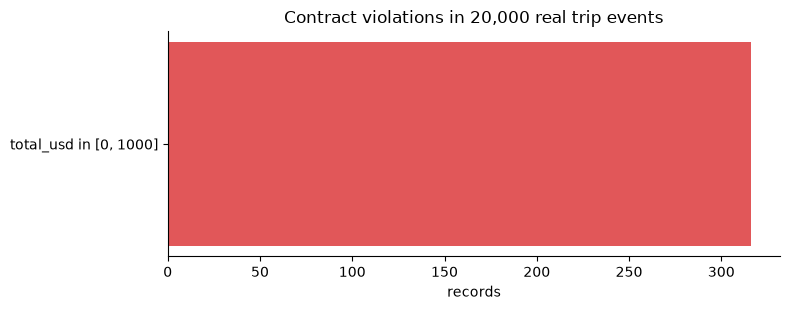

In [6]:
CONTRACT = yaml.safe_load("""
apiVersion: v3.0.2
kind: DataContract
id: nyc-taxi-trips
name: Taxi trip events
version: 1.1.0
status: active
owner: mobility-data-team
contact: "#mobility-data (Slack), on-call: data-oncall@example.com"
description: One event per completed yellow-taxi trip, published within 5 minutes of drop-off.
schema:
  - name: trips-avro
    physicalType: kafka-topic
    properties:
      - {name: trip_id,        logicalType: integer, required: true, unique: true}
      - {name: pickup_at,      logicalType: timestamp, required: true}
      - {name: pu_zone,        logicalType: integer, required: true, quality: [{rule: between, min: 1, max: 265}]}
      - {name: do_zone,        logicalType: integer, required: true, quality: [{rule: between, min: 1, max: 265}]}
      - {name: distance_miles, logicalType: number,  required: true, quality: [{rule: between, min: 0, max: 200}]}
      - {name: total_usd,      logicalType: number,  required: true, quality: [{rule: between, min: 0, max: 1000}]}
slaProperties:
  - {property: latency, value: 5, unit: minutes}
  - {property: retention, value: 7, unit: days}
""")

def validate(rows: list[dict], contract: dict) -> pd.DataFrame:
    props = contract["schema"][0]["properties"]
    df = pd.DataFrame(rows)
    out = []
    for p in props:
        col = p["name"]
        if p.get("required"):
            out.append({"rule": f"{col} required", "violations": int(df[col].isna().sum()) if col in df else len(df)})
        if p.get("unique") and col in df:
            out.append({"rule": f"{col} unique", "violations": int(df[col].duplicated().sum())})
        for q in p.get("quality", []):
            if q["rule"] == "between" and col in df:
                bad = ~df[col].between(q["min"], q["max"])
                out.append({"rule": f"{col} in [{q['min']}, {q['max']}]", "violations": int(bad.sum())})
    return pd.DataFrame(out)

report = validate(records, CONTRACT)
print(f"contract {CONTRACT['id']} v{CONTRACT['version']} (owner: {CONTRACT['owner']})")
print(report.to_string(index=False))
print(f"\n{(report.violations > 0).sum()} of {len(report)} rules violated, {report.violations.sum()} violations in {len(records):,} records")

plt.figure(figsize=(8, 3.2))
viol = report[report.violations > 0]
plt.barh(viol.rule, viol.violations, color="#E15759")
plt.title("Contract violations in 20,000 real trip events"); plt.xlabel("records")
plt.tight_layout(); plt.show()

*Insight: Real data breaks rules nobody wrote down: all zone IDs are valid, but 316 trips have a negative total (refunds and voids), and the rule `total_usd in [0, 1000]` treats them as errors. A contract makes these rules explicit, so producer and consumers agree whether to fix, filter or model them.*

## Real-World Use Case or Analogy

A schema registry is like **the electrical plug standard**: any device (consumer) fits any socket (topic) as long
as both follow the standard, and a new device type is allowed only if old sockets still work. A data contract is the
full **rental agreement** around the socket: voltage limits, who repairs it and how fast.

Large companies with hundreds of event streams make the registry mandatory (producers cannot write without a
registered, compatible schema) and keep contracts in Git next to the producer's code, checked in CI.